# 00.4 · The 7-step ML workflow

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/00-big-picture/04-ml-workflow/lesson.ipynb)

Read the [README](README.md) first. This notebook walks the seven steps on the 20-customer table, one cell per step, in miniature. The numbers are toy-sized; the *sequence* is what every real project follows.

## Step 1 · Frame

Written down before any code. (In a real project this is a shared document.)

| | |
|---|---|
| Decision | send a voucher to customers likely to churn |
| Unit | one customer, as of today |
| Target | `churned` = 1 if no order in the next 90 days |
| Features | things known **today**: visits, items, days since last order, country |
| Metric | accuracy for now (Module 03 gives better ones) |
| Baseline | "flag everyone with `days_since_last` > 30" |

## Step 2 · Get the data

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd
cust = pd.read_csv(data_path("shopwave_customers_small.csv"))

print(cust.shape, "customers × columns")
cust.head()

(20, 7) customers × columns


,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1


## Step 3 · Explore

Counts and one picture. Is the target balanced? Does anything look odd?

churned
0    11
1     9
Name: customers, dtype: int64

missing values per column:
 customer_id          0
visits_last_month    0
items_last_month     0
days_since_last      0
country              0
spend_next_month     0
churned              0
dtype: int64


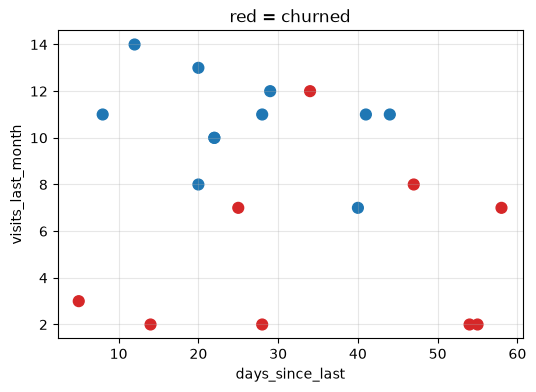

In [2]:
import matplotlib.pyplot as plt
print(cust["churned"].value_counts().rename("customers"))
print("\nmissing values per column:\n", cust.isna().sum())

cust.plot.scatter(x="days_since_last", y="visits_last_month", c=cust["churned"].map({0: "tab:blue", 1: "tab:red"}),
                  s=60, figsize=(6, 4), title="red = churned")
plt.grid(alpha=.3); plt.show()

## Step 4 · Prepare

Encode the one text column, choose features, and **split** so the test rows stay unseen until Step 6.

In [3]:
from sklearn.model_selection import train_test_split

data = pd.get_dummies(cust, columns=["country"], dtype=int)      # UK/DE/FR -> three 0/1 columns
features = ["visits_last_month", "items_last_month", "days_since_last", "country_DE", "country_FR", "country_UK"]
X, y = data[features], data["churned"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print(f"train: {len(X_train)} customers, test: {len(X_test)} customers (hidden until Step 6)")

train: 14 customers, test: 6 customers (hidden until Step 6)


## Step 5 · Model

Start simple. One decision tree.

In [4]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_train, y_train)
print("trained on", len(X_train), "customers")

trained on 14 customers


## Step 6 · Evaluate

On the hidden test rows, and against the baseline.

In [5]:
baseline_pred = (X_test["days_since_last"] > 30).astype(int)
model_pred = model.predict(X_test)

print(f"baseline accuracy on test: {(baseline_pred == y_test).mean():.0%}")
print(f"model    accuracy on test: {(model_pred == y_test).mean():.0%}")

baseline accuracy on test: 67%
model    accuracy on test: 83%


With 6 test customers these percentages jump around a lot; Module 04 shows cross-validation, which fixes that. The habit to take away: **test rows the model never saw, compared to a baseline.**

## Step 7 · Deploy and monitor

Save the model, load it somewhere else, predict for a new customer. (Monitoring comes in Module 10.)

In [6]:
import joblib
joblib.dump(model, "churn_model.joblib")
loaded = joblib.load("churn_model.joblib")

new_customer = pd.DataFrame([{"visits_last_month": 3, "items_last_month": 1, "days_since_last": 45,
                              "country_DE": 0, "country_FR": 0, "country_UK": 1}])
print("new customer churn prediction:", loaded.predict(new_customer)[0], "(1 = likely to churn)")

new customer churn prediction: 1 (1 = likely to churn)


## The trap: time flows one way

Below is a feature that would be easy to build by accident: `days_since_last_now`, measured **today**, 90 days after the prediction date. For customers who churned it is large by definition. Watch what it does to the score.

In [7]:
import numpy as np
rng = np.random.default_rng(0)
leaky = data.copy()
# measured AFTER the 90-day window: churners have had no order, so the gap grew by 90 days
leaky["days_since_last_now"] = np.where(leaky["churned"] == 1,
                                        leaky["days_since_last"] + 90,
                                        rng.integers(1, 30, len(leaky)))

Xl = leaky[features + ["days_since_last_now"]]
Xl_train, Xl_test, yl_train, yl_test = train_test_split(Xl, y, test_size=0.3, random_state=0, stratify=y)
leaky_model = DecisionTreeClassifier(max_depth=2, random_state=0).fit(Xl_train, yl_train)
print(f"LEAKY model accuracy on test: {(leaky_model.predict(Xl_test) == yl_test).mean():.0%}")

from sklearn.tree import export_text
print(export_text(leaky_model, feature_names=list(Xl.columns)))

LEAKY model accuracy on test: 100%
|--- days_since_last_now <= 62.00
|   |--- class: 0
|--- days_since_last_now >  62.00
|   |--- class: 1



Perfect score, one split, on a feature that **cannot exist at prediction time** (you would need to wait 90 days to measure it, by which time you know the answer anyway). The honest model above scores lower, and it is the only one worth shipping.

A legal version of the same idea: `days_since_last` measured **on the prediction date**, which is exactly what the honest model already uses.

## Quiz answers

1. Frame → get data → explore → prepare → model → evaluate → deploy and monitor.
2. A feature may only be used if its value was known *before* the moment the prediction is needed. Nothing from after that moment is allowed.
3. Without a baseline you cannot tell whether 90% accuracy is impressive or trivial; it also forces you to define the metric and target before modelling.
4. Step 1, framing: the decision, unit, target, metric and baseline.
5. Value is created only when a prediction changes a decision. A model nobody runs changes nothing.

**Next:** [00.5 The whole course in one notebook](../05-whole-course-in-one-notebook/)